# Инкрементальный MeshA*: расширенные C++-эксперименты

11 методов; replay на одинаковых запросах и отдельная навигация по неизвестному миру. Этот ноутбук читает готовые нативные измерения, проверяет их хеши и позволяет менять парное сравнение. Времена Python и первого остановленного прохода не участвуют.

[Полный отчёт](report.md) · [PDF](report.pdf) · [Протокол](protocol.md) · [Исходники и словарь данных](../../cpp/experiments/README.md)

Параметризованные случаи с одним корнем зависимы. Превышение бюджета не равно недостижимости; короткий неоконченный проезд не считается высоким качеством.

In [1]:
from pathlib import Path
import csv, hashlib, json, statistics
from IPython.display import display, Markdown, Image

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'cpp/experiments/frozen/manifest.json').exists())
directory = root / 'cpp/experiments/results/expanded'
analysis = json.loads((directory / 'analysis/analysis.json').read_text())
state = json.loads((directory / 'experiment.json').read_text())
assert analysis['status'] == state['status'] == 'passed'
for name, sha in analysis['raw_sha256'].items():
    assert hashlib.sha256((directory / name).read_bytes()).hexdigest() == sha, name
with (directory / 'analysis/episode_metrics.csv').open() as f:
    episodes = list(csv.DictReader(f))
print(f"{analysis['replay_cases']} replay, {analysis['mission_cases']} missions; "
      f"{analysis['timed_episode_runs']} timed runs; {analysis['cap_rows']} capped attempts (repeats included)")
print('Memory decisions:', analysis['allocation_decision_parity'])

186 replay, 40 missions; 7458 timed runs; 54 capped attempts (repeats included)
Memory decisions: passed


In [2]:
def table(headers, rows):
    text = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    text += ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(text)))

def ratio(z):
    return '—' if not z['n'] else f"{z['median']:.3f}× ({z['n']}/{z['total']})"

table(['Group', 'MPGAA/MD episode', 'MPGAA/MD repairs', 'LBA reuse/MD episode'],
      [[key, ratio(info['md_vs_mpgaa']['episode_s']), ratio(info['md_vs_mpgaa']['online_s']),
        ratio(info['md_vs_reuse']['episode_s'])] for key, info in analysis['groups'].items()])

| Group | MPGAA/MD episode | MPGAA/MD repairs | LBA reuse/MD episode |
| --- | --- | --- | --- |
| car16:churn | 1.089× (11/12) | 1.112× (11/12) | 0.974× (11/12) |
| car16:history | 31.798× (4/4) | 171.053× (4/4) | 9.815× (4/4) |
| car16:off_path | 1.083× (12/12) | 23.509× (12/12) | 0.597× (12/12) |
| car16:on_path | 1.041× (12/12) | 1.036× (12/12) | 0.512× (12/12) |
| car16:unknown_mission | 1.129× (15/16) | 1.130× (15/16) | 0.459× (15/16) |
| car16:unknown_replay | 1.080× (12/12) | 1.118× (12/12) | 0.461× (12/12) |
| grid8:paper_dynamic | 1.046× (96/96) | 1.127× (92/96) | 0.996× (96/96) |
| grid8:unknown_mission | 1.073× (24/24) | 1.147× (24/24) | 1.027× (24/24) |

## Где выигрывает ремонт

Значения больше 1 означают ускорение MD. Отношения считаются только на парах, завершённых обоими методами; доли завершения обязательно учитывать отдельно. На чистых вставках сохранение допустимого оптимального суффикса доступно стандартному A*. Неизвестная статическая карта не содержит освобождений, поэтому на ней не проверяется новый механизм их отсрочки.

In [3]:
table(['Control', 'Map', 'Regime', 'Fastest complete exact', 'MPGAA/MD', 'Reuse/MD'],
      [[r['control'], r['map'], r['family'], r['best_complete_exact'], ratio(r['md_vs_mpgaa']),
        ratio(r['md_vs_reuse'])] for r in analysis['map_results']])

| Control | Map | Regime | Fastest complete exact | MPGAA/MD | Reuse/MD |
| --- | --- | --- | --- | --- | --- |
| car16 | AR0700 | churn | md_astar | 1.063× (2/2) | 1.246× (2/2) |
| car16 | AR0700 | off_path | lba_reuse | 1.008× (2/2) | 0.633× (2/2) |
| car16 | AR0700 | on_path | lba_reuse | 0.984× (2/2) | 0.491× (2/2) |
| car16 | AR0700 | unknown_replay | lba_reuse | 1.020× (2/2) | 0.467× (2/2) |
| car16 | Berlin | churn | dstar_lattice | 1.089× (1/2) | 2.679× (1/2) |
| car16 | Berlin | off_path | lba_reuse | 0.997× (2/2) | 0.611× (2/2) |
| car16 | Berlin | on_path | lba_reuse | 0.982× (2/2) | 0.848× (2/2) |
| car16 | Berlin | unknown_replay | lba_reuse | 1.058× (2/2) | 0.536× (2/2) |
| car16 | MA_maze96 | churn | mpgaa | 0.877× (2/2) | 1.707× (2/2) |
| car16 | MA_maze96 | off_path | lba_reuse | 0.992× (2/2) | 0.393× (2/2) |
| car16 | MA_maze96 | on_path | lba_reuse | 1.150× (2/2) | 0.734× (2/2) |
| car16 | MA_maze96 | unknown_mission | None | 1.002× (3/4) | 0.745× (3/4) |
| car16 | MA_maze96 | unknown_replay | lba_reuse | 1.057× (2/2) | 0.432× (2/2) |
| car16 | MA_random96 | churn | lba_reuse | 1.147× (2/2) | 0.687× (2/2) |
| car16 | MA_random96 | off_path | lba_reuse | 1.387× (2/2) | 0.610× (2/2) |
| car16 | MA_random96 | on_path | dstar_lattice | 1.079× (2/2) | 0.396× (2/2) |
| car16 | MA_random96 | unknown_mission | lba_reuse | 1.204× (4/4) | 0.305× (4/4) |
| car16 | MA_random96 | unknown_replay | lba_reuse | 1.082× (2/2) | 0.493× (2/2) |
| car16 | MA_room96 | churn | md_scan | 1.003× (2/2) | 1.184× (2/2) |
| car16 | MA_room96 | off_path | lba_reuse | 1.171× (2/2) | 0.557× (2/2) |
| car16 | MA_room96 | on_path | lba_reuse | 0.951× (2/2) | 0.362× (2/2) |
| car16 | MA_room96 | unknown_mission | lba_reuse | 1.033× (4/4) | 0.424× (4/4) |
| car16 | MA_room96 | unknown_replay | lba_reuse | 1.152× (2/2) | 0.554× (2/2) |
| car16 | arena | churn | lazy_lba | 1.485× (2/2) | 0.423× (2/2) |
| car16 | arena | off_path | lba_reuse | 6.587× (2/2) | 0.592× (2/2) |
| car16 | arena | on_path | lba_reuse | 1.058× (2/2) | 0.521× (2/2) |
| car16 | arena | unknown_mission | lba_reuse | 6.252× (4/4) | 0.559× (4/4) |
| car16 | arena | unknown_replay | lba_reuse | 3.006× (2/2) | 0.546× (2/2) |
| car16 | synthetic_open96 | history | md64 | 31.798× (4/4) | 9.815× (4/4) |
| grid8 | random50_p10 | paper_dynamic | md_astar | 1.068× (24/24) | 1.194× (24/24) |
| grid8 | random50_p10 | unknown_mission | md64 | 1.123× (6/6) | 0.963× (6/6) |
| grid8 | random50_p20 | paper_dynamic | md_astar | 1.110× (24/24) | 0.961× (24/24) |
| grid8 | random50_p20 | unknown_mission | lba_reuse | 1.106× (6/6) | 0.669× (6/6) |
| grid8 | random50_p30 | paper_dynamic | md_astar | 1.055× (24/24) | 1.281× (24/24) |
| grid8 | random50_p30 | unknown_mission | md64 | 1.001× (6/6) | 1.494× (6/6) |
| grid8 | random50_p40 | paper_dynamic | mpgaa | 0.965× (24/24) | 0.756× (24/24) |
| grid8 | random50_p40 | unknown_mission | md_astar | 0.996× (6/6) | 1.376× (6/6) |

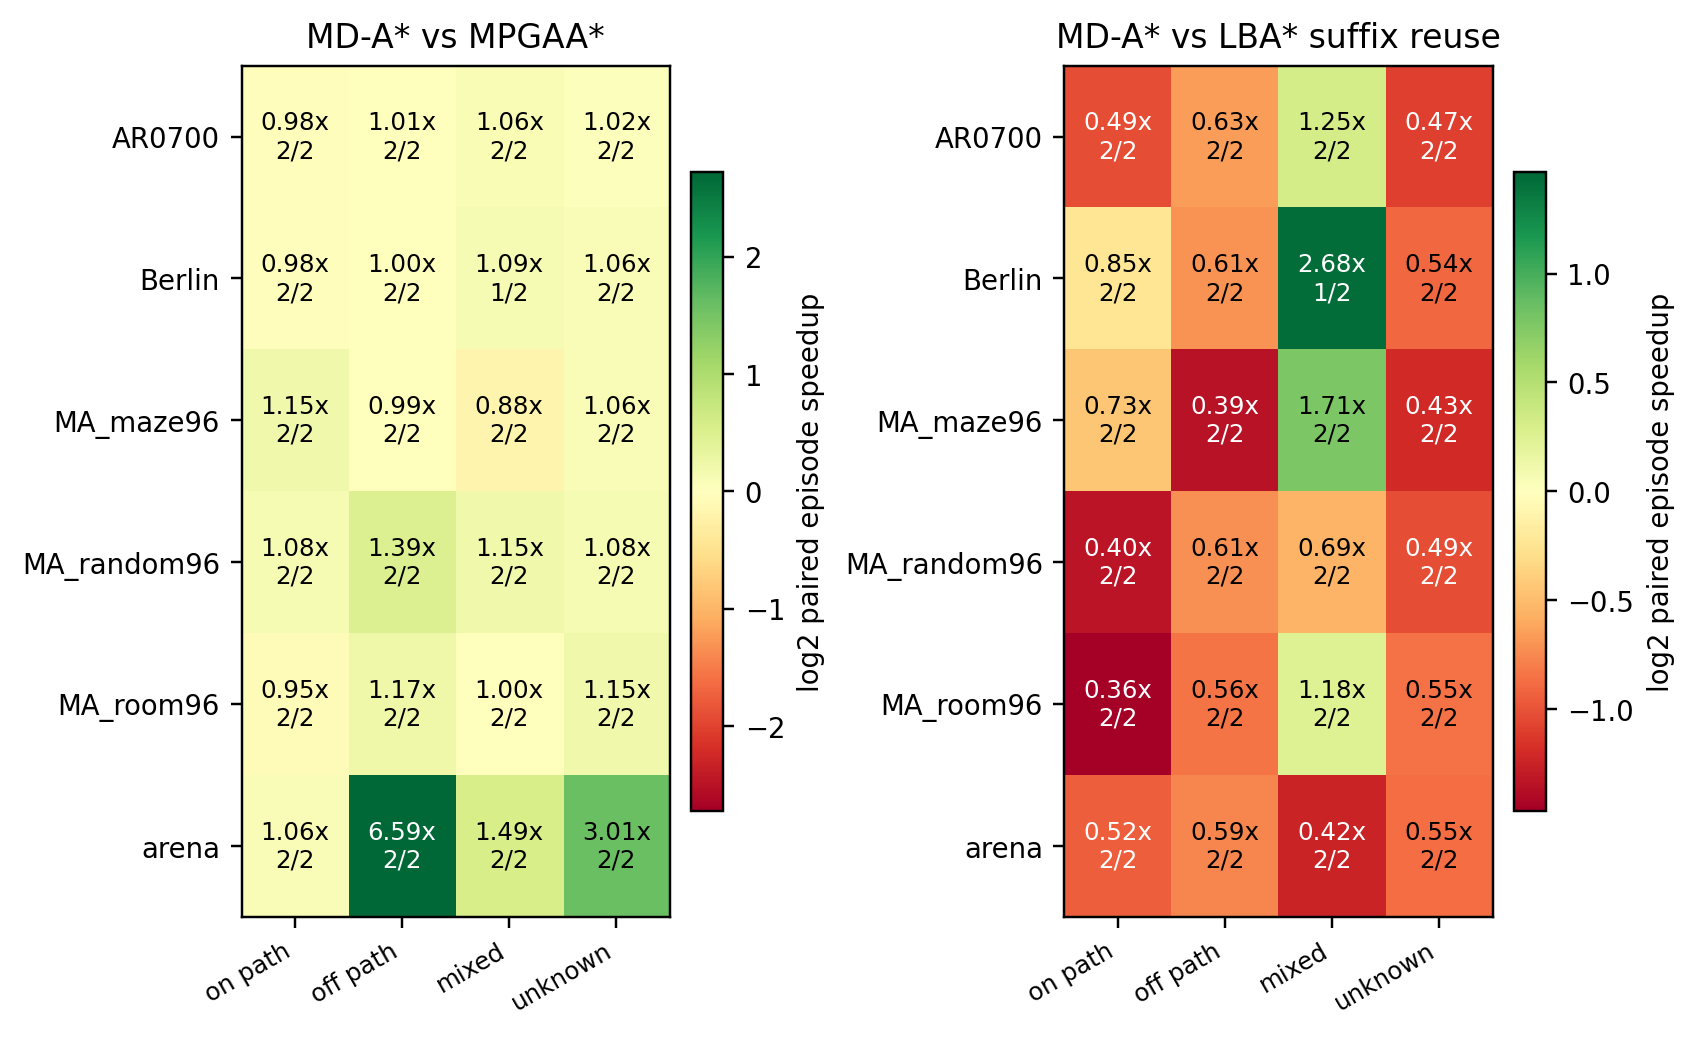

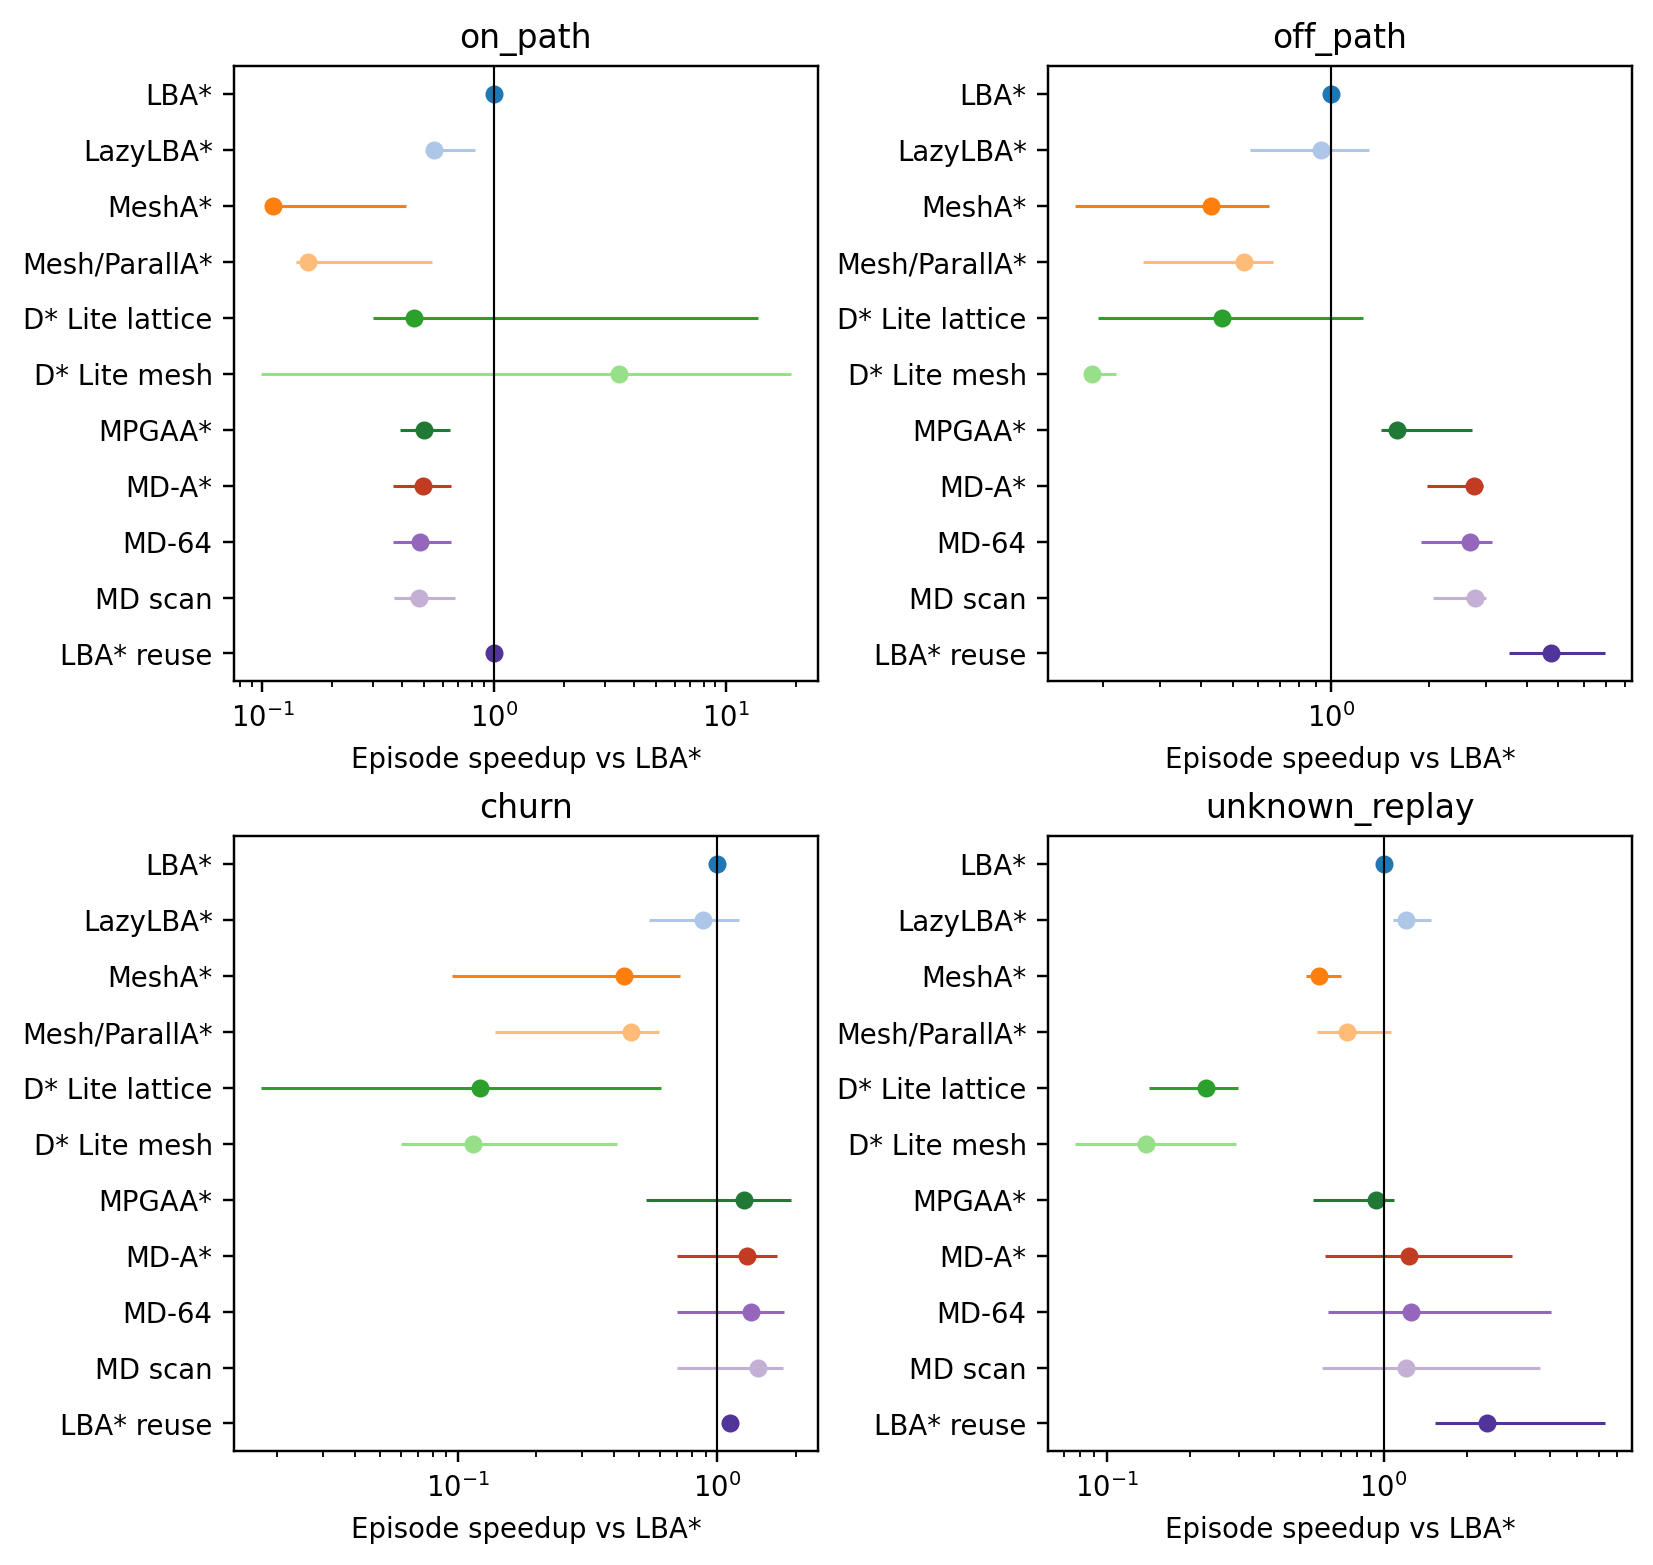

In [4]:
display(Image(filename=str(root / 'docs/experiments/figures/map_regimes.png')))
display(Image(filename=str(root / 'docs/experiments/figures/all_methods.png')))

## Завершение и неизвестная карта

В replay доказанный `no_path` — полный корректный вычисленный ответ. В миссии завершение означает достижение цели. При навигации методы получают разные наблюдения, потому что выбирают разные пути. Отношение пройденной длины к оптимуму с полной информацией описывает цену исследования.

| Control/task | Method | Complete/all | Cap | Step limit | No path |
| --- | --- | --- | --- | --- | --- |
| car16/replay | lba | 90/90 | 0 | 0 | 16 |
| car16/replay | lazy_lba | 90/90 | 0 | 0 | 16 |
| car16/replay | mesha | 88/90 | 2 | 0 | 14 |
| car16/replay | mesh_parall | 88/90 | 2 | 0 | 14 |
| car16/replay | dstar_lattice | 90/90 | 0 | 0 | 16 |
| car16/replay | dstar_mesh | 79/90 | 11 | 0 | 12 |
| car16/replay | mpgaa | 90/90 | 0 | 0 | 16 |
| car16/replay | md_astar | 89/90 | 1 | 0 | 15 |
| car16/replay | md64 | 89/90 | 1 | 0 | 15 |
| car16/replay | md_scan | 89/90 | 1 | 0 | 15 |
| car16/replay | lba_reuse | 90/90 | 0 | 0 | 16 |
| car16/mission | lba | 15/16 | 0 | 1 | 0 |
| car16/mission | lazy_lba | 15/16 | 0 | 1 | 0 |
| car16/mission | mesha | 15/16 | 0 | 1 | 0 |
| car16/mission | mesh_parall | 15/16 | 0 | 1 | 0 |
| car16/mission | dstar_lattice | 15/16 | 0 | 1 | 0 |
| car16/mission | dstar_mesh | 15/16 | 0 | 1 | 0 |
| car16/mission | mpgaa | 15/16 | 0 | 1 | 0 |
| car16/mission | md_astar | 15/16 | 0 | 1 | 0 |
| car16/mission | md64 | 15/16 | 0 | 1 | 0 |
| car16/mission | md_scan | 15/16 | 0 | 1 | 0 |
| car16/mission | lba_reuse | 15/16 | 0 | 1 | 0 |
| grid8/replay | lba | 96/96 | 0 | 0 | 1 |
| grid8/replay | lazy_lba | 96/96 | 0 | 0 | 1 |
| grid8/replay | mesha | 96/96 | 0 | 0 | 1 |
| grid8/replay | mesh_parall | 96/96 | 0 | 0 | 1 |
| grid8/replay | dstar_lattice | 96/96 | 0 | 0 | 1 |
| grid8/replay | dstar_mesh | 96/96 | 0 | 0 | 1 |
| grid8/replay | mpgaa | 96/96 | 0 | 0 | 1 |
| grid8/replay | md_astar | 96/96 | 0 | 0 | 1 |
| grid8/replay | md64 | 96/96 | 0 | 0 | 1 |
| grid8/replay | md_scan | 96/96 | 0 | 0 | 1 |
| grid8/replay | lba_reuse | 96/96 | 0 | 0 | 1 |
| grid8/mission | lba | 24/24 | 0 | 0 | 0 |
| grid8/mission | lazy_lba | 24/24 | 0 | 0 | 0 |
| grid8/mission | mesha | 24/24 | 0 | 0 | 0 |
| grid8/mission | mesh_parall | 24/24 | 0 | 0 | 0 |
| grid8/mission | dstar_lattice | 24/24 | 0 | 0 | 0 |
| grid8/mission | dstar_mesh | 24/24 | 0 | 0 | 0 |
| grid8/mission | mpgaa | 24/24 | 0 | 0 | 0 |
| grid8/mission | md_astar | 24/24 | 0 | 0 | 0 |
| grid8/mission | md64 | 24/24 | 0 | 0 | 0 |
| grid8/mission | md_scan | 24/24 | 0 | 0 | 0 |
| grid8/mission | lba_reuse | 24/24 | 0 | 0 | 0 |

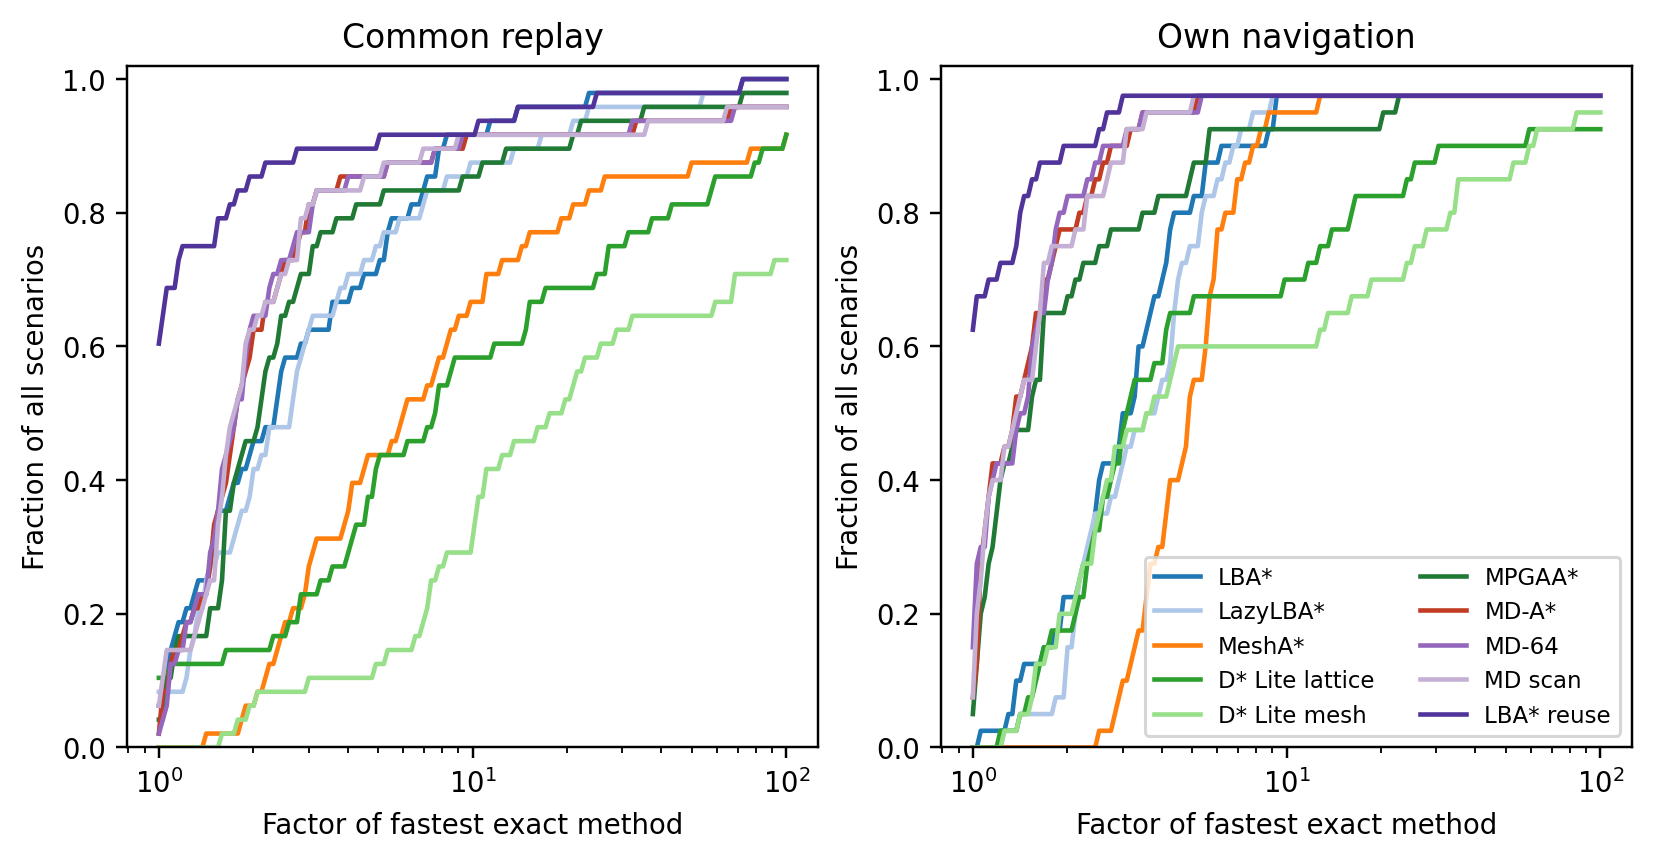

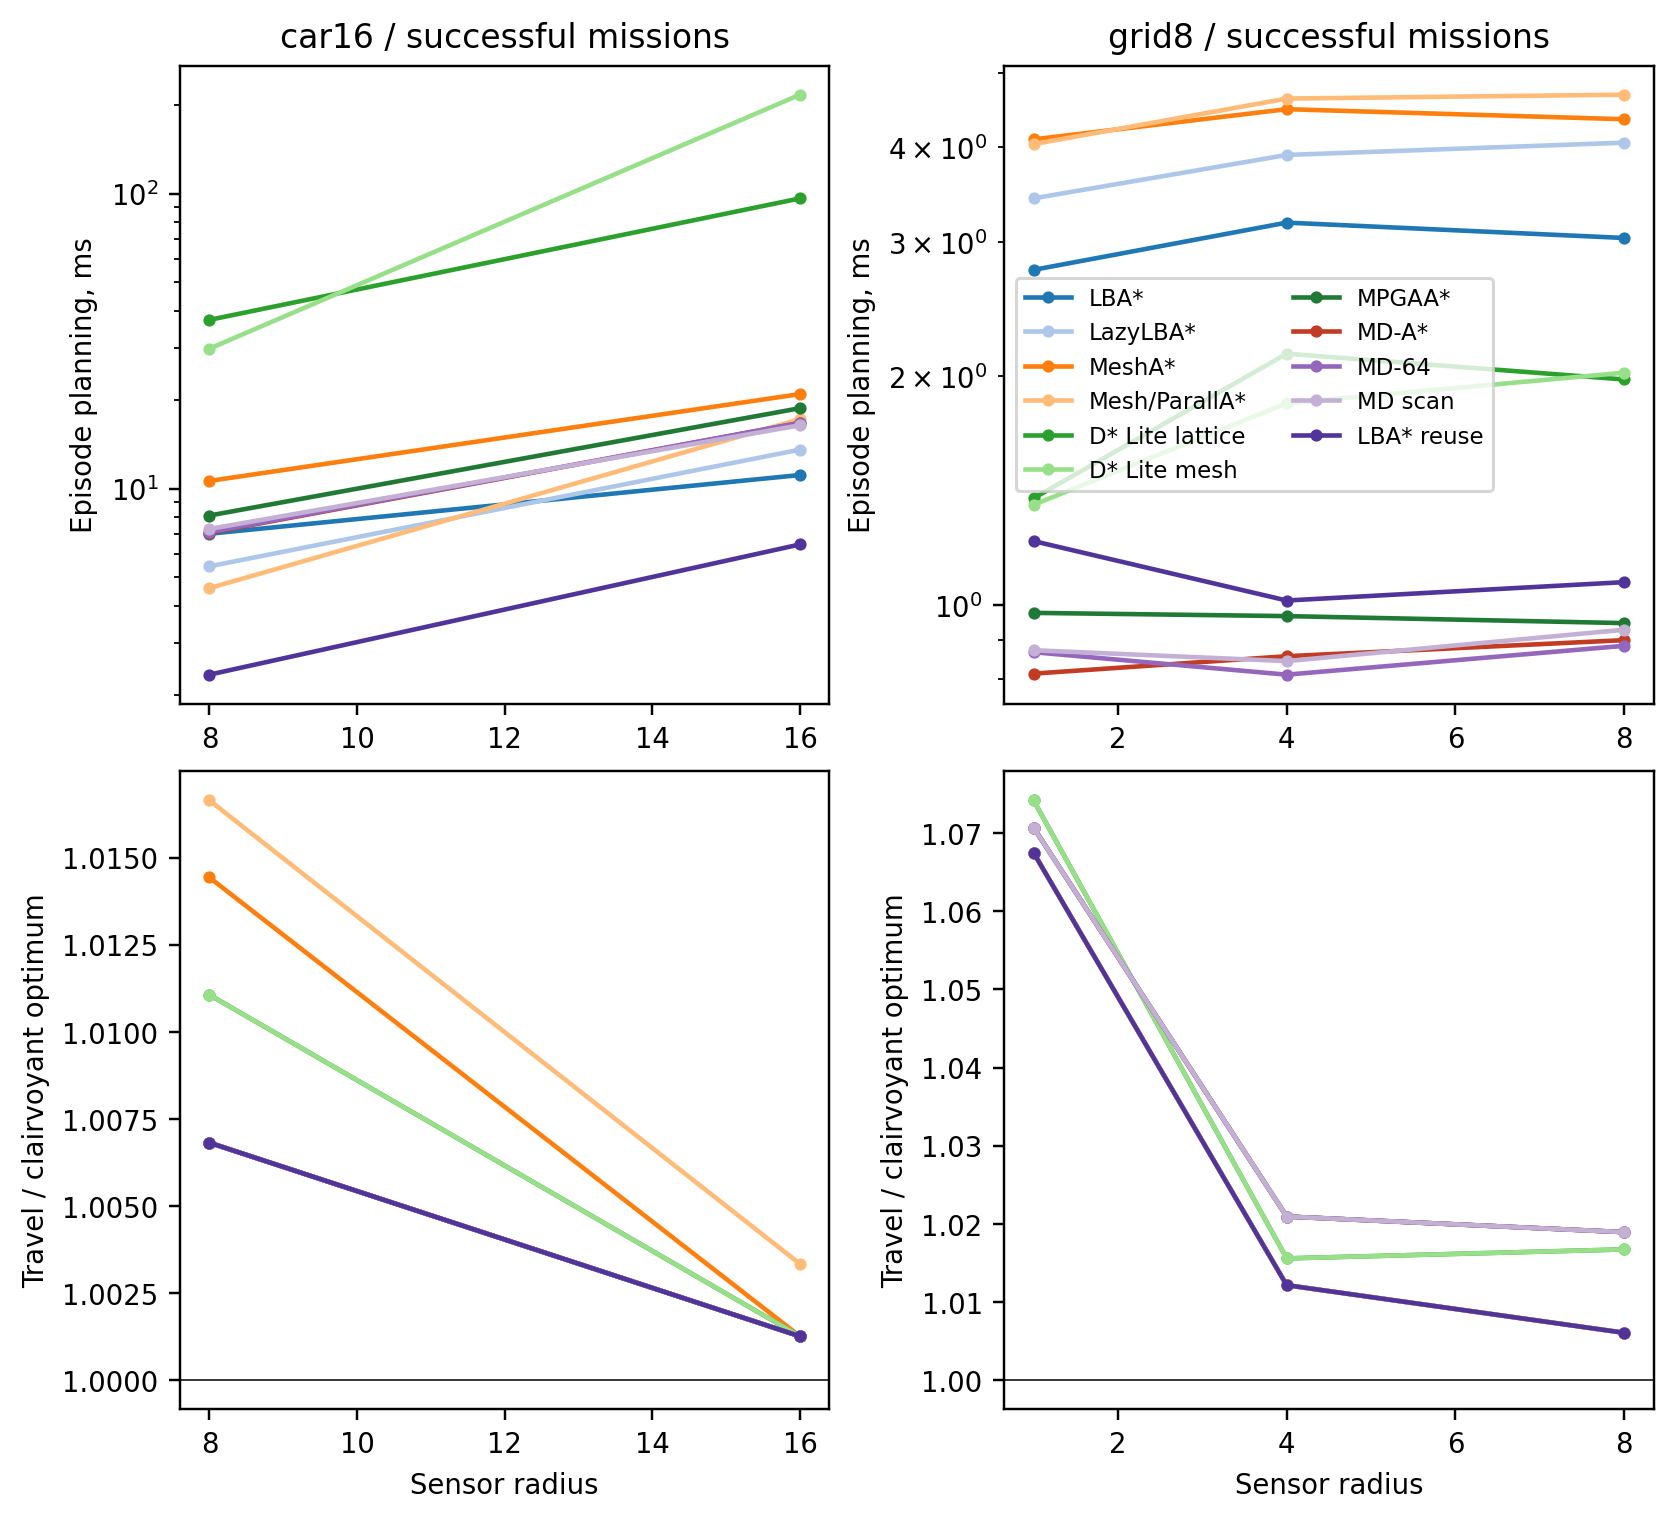

In [5]:
table(['Control/task', 'Method', 'Complete/all', 'Cap', 'Step limit', 'No path'],
      [[r['control'] + '/' + r['mode'], r['method'], f"{r['completed']}/{r['total']}", r['capped'],
        r['step_limit'], r['no_path']] for r in analysis['outcomes']])
display(Image(filename=str(root / 'docs/experiments/figures/performance_profiles.png')))
display(Image(filename=str(root / 'docs/experiments/figures/unknown_visibility.png')))

## Настраиваемое парное сравнение

Измените переменные в следующей ячейке. Сравниваются медианные эпизодные суммы на одних и тех же случаях. `metric='online_s'` исключает первичный поиск, `episode_s` включает конструктор и первый поиск. `peak_heap_bytes` — отдельный проход запрошенной C++ heap-памяти, не RSS. Не смешивайте replay и собственную навигацию.

In [6]:
control, family = 'car16', 'churn'
candidate, baseline, metric = 'md_astar', 'mpgaa', 'online_s'
meta = {}
for path in (root / 'cpp/experiments/frozen').glob('*.contexts.json'):
    for c in json.loads(path.read_text())['cases']:
        meta[c['id']] = c
selected = [r for r in episodes if r['control'] == control and r['family'] == family]
if control == 'car16' and family in ['on_path', 'off_path', 'churn', 'unknown_replay']:
    selected = [r for r in selected if 'main' in meta[r['case']]['panels']]
index = {(r['case'], r['method']): r for r in selected}
ratios, total = [], len({r['case'] for r in selected})
for case in sorted({r['case'] for r in selected}):
    a, b = index[case, candidate], index[case, baseline]
    if a['complete'] == b['complete'] == 'True' and float(a[metric]) > 0 and float(b[metric]) > 0:
        ratios.append((case, float(b[metric]) / float(a[metric])))
table(['Scenario', f'{baseline}/{candidate}'], [[name, f'{v:.3f}×'] for name, v in ratios])
print('Paired complete:', len(ratios), '/', total)
print('Median:', statistics.median(v for _, v in ratios) if ratios else None)

| Scenario | mpgaa/md_astar |
| --- | --- |
| car16__AR0700__churn__s48101__b8__k2__r8 | 1.111× |
| car16__AR0700__churn__s48102__b8__k2__r8 | 1.152× |
| car16__Berlin__churn__s48101__b8__k2__r8 | 1.112× |
| car16__MA_maze96__churn__s48101__b8__k2__r8 | 0.697× |
| car16__MA_maze96__churn__s48102__b8__k2__r8 | 0.886× |
| car16__MA_random96__churn__s48101__b8__k2__r8 | 1.303× |
| car16__MA_random96__churn__s48102__b8__k2__r8 | 1.120× |
| car16__MA_room96__churn__s48101__b8__k2__r8 | 0.818× |
| car16__MA_room96__churn__s48102__b8__k2__r8 | 1.091× |
| car16__arena__churn__s48101__b8__k2__r8 | 1.695× |
| car16__arena__churn__s48102__b8__k2__r8 | 1.455× |

Paired complete: 11 / 12
Median: 1.111802596094289


## Масштабирование и воспроизводимость

Ось числа правок использует доставленные изменения карты знаний. Номинальная доля глобальных изменений не равна этому числу; при недостатке исходно занятых клеток бюджет ограничивается доступным пулом. Графики задержек условны на запросах, закончившихся в бюджете. Все 16 фигур доступны отдельно в PNG/PDF в `figures/`.

Для полного повторения используйте `cpp/experiments/run_all.py` в новый каталог. Подготовка и модель заморожены до замеров. В экспериментальном D* Lite исправлена численная граница остановки; первый остановленный проход сохранён отдельно и исключён из этих результатов.

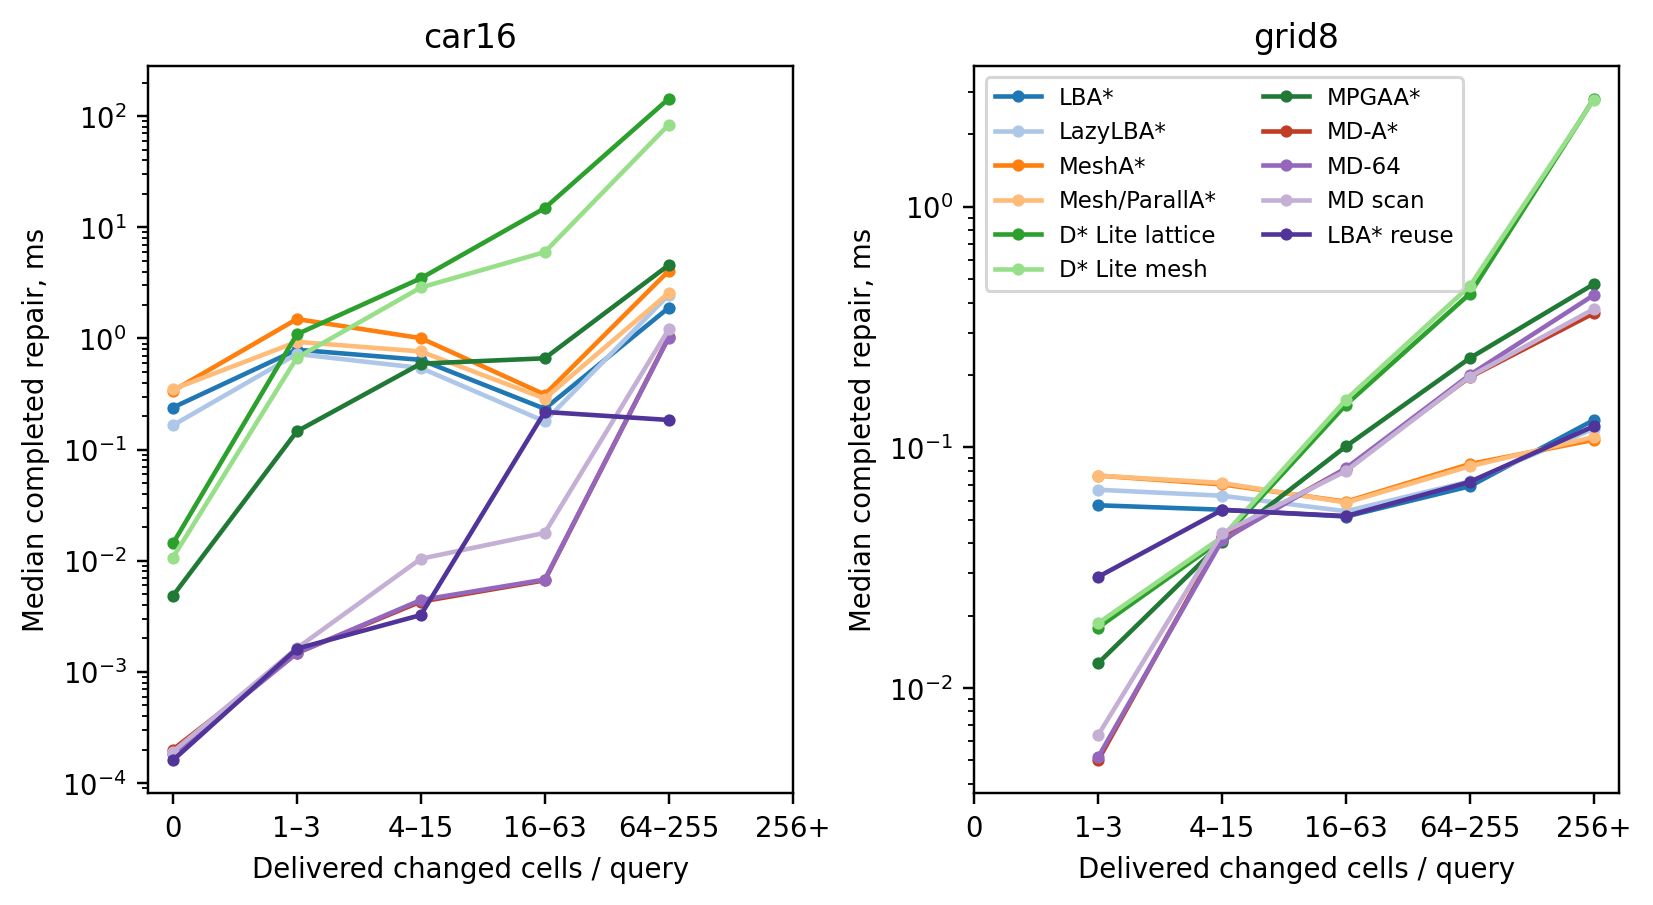

Measured source hashes:
cpp/experiments/bench.cpp ce6ae2a30d499d44
cpp/experiments/dstar_boundary.hpp 959a21c8684f7890
cpp/experiments/memory.hpp 16a8f7e99fc79b35
cpp/experiments/Makefile c0c05bf56639225b
cpp/include/ima/adaptive.hpp 5c54db0b17695392
cpp/include/ima/deferred.hpp d4b47e481e323e1e
cpp/include/ima/dstar.hpp c9e9b714fbf86da1
cpp/include/ima/model.hpp ce03a8bbb71cb873
cpp/include/ima/planners.hpp b874588434c7bbb5
cpp/include/ima/search.hpp cdc94b7a4a9897e4


In [7]:
display(Image(filename=str(root / 'docs/experiments/figures/change_scaling.png')))
print('Measured source hashes:')
for path, sha in state['source_sha256'].items():
    assert hashlib.sha256((root / path).read_bytes()).hexdigest() == sha
    print(path, sha[:16])